In [1]:
import pandas as pd
import os
import textdistance
import seaborn as sns
import matplotlib.pyplot as plt
from unidecode import unidecode
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import re

In [2]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /home/corey/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/corey/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
# Set the directory where your CSV files are located
folder_path = '../data/vivino/similarity_href_subsets'

# Get a list of all CSV files in the folder
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

# Initialize an empty list to store individual dataframes
dfs = []

# Loop through each CSV file, read it into a dataframe, and append it to the list
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dfs.append(df)

# Concatenate all dataframes into one
matching_df = pd.concat(dfs, ignore_index=True)

In [4]:
# Drop rows where "cleanskin" appears as a substring in either name column, ignoring case
#matching_df = matching_df[~(matching_df['dm_product_name'].str.contains('cleanskin', case=False) | matching_df['vivino_product_name'].str.contains('cleanskin', case=False))].reset_index(drop=True)

In [5]:
#matching_df = matching_df[matching_df["dm_brand_name"] == "Sit Stay Society"]

In [6]:
matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715
4,Illuminati,ilico Montepulciano d'Abruzzo,https://www.danmurphys.com.au/product/DM_91724...,Illuminati Ilico,https://www.vivino.com/AU/en/wines/1469260
...,...,...,...,...,...
6052,Elephant In The Room,Tempranillo,https://www.danmurphys.com.au/product/DM_86526...,Elephant In The Room Titanic Tempranillo,https://www.vivino.com/AU/en/wines/165182546
6053,Brown Brothers,Winemakers Series Tempranillo Graciano,https://www.danmurphys.com.au/product/DM_86491...,Brown Brothers Winemaker’S Series Tempranillo ...,https://www.vivino.com/AU/en/wines/165373677
6054,Noble Fellows,Colonel Kiwi Marlborough Pinot Noir,https://www.danmurphys.com.au/product/DM_86484...,Noble Fellows Colonel Kiwi Pinot Noir,https://www.vivino.com/AU/en/wines/161072244
6055,Distant South,Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_86462...,Distant South Pinot Noir,https://www.vivino.com/AU/en/wines/160780353


### Calculate similarity

In [7]:
matching_df = matching_df[matching_df['vivino_product_name'].notna()].reset_index(drop=True)
matching_df[matching_df["vivino_product_name"].isna()]

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href


In [8]:
def remove_punctuation(text):
    return re.sub(r'[^\w\s]', '', text)

def remove_spaces(text):
    return re.sub(r'\s+', '', text)
    
def calculate_brand_name_presence(row):
    dm_brand_name = remove_spaces(remove_punctuation(unidecode(row["dm_brand_name"].lower())))
    vivino_product_name = remove_spaces(remove_punctuation(unidecode(row["vivino_product_name"].lower())))
    if dm_brand_name in vivino_product_name:
        return True
    else:
        return False

matching_df['brand_present'] = matching_df.apply(calculate_brand_name_presence, axis=1)

In [9]:
matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758,True
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True
4,Illuminati,ilico Montepulciano d'Abruzzo,https://www.danmurphys.com.au/product/DM_91724...,Illuminati Ilico,https://www.vivino.com/AU/en/wines/1469260,True
...,...,...,...,...,...,...
6050,Elephant In The Room,Tempranillo,https://www.danmurphys.com.au/product/DM_86526...,Elephant In The Room Titanic Tempranillo,https://www.vivino.com/AU/en/wines/165182546,True
6051,Brown Brothers,Winemakers Series Tempranillo Graciano,https://www.danmurphys.com.au/product/DM_86491...,Brown Brothers Winemaker’S Series Tempranillo ...,https://www.vivino.com/AU/en/wines/165373677,True
6052,Noble Fellows,Colonel Kiwi Marlborough Pinot Noir,https://www.danmurphys.com.au/product/DM_86484...,Noble Fellows Colonel Kiwi Pinot Noir,https://www.vivino.com/AU/en/wines/161072244,True
6053,Distant South,Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_86462...,Distant South Pinot Noir,https://www.vivino.com/AU/en/wines/160780353,True


In [10]:
percentage_unbranded = (len(matching_df[matching_df["brand_present"] == False]) / len(matching_df))
print("percentage of vivino results missing brand:", percentage_unbranded)
matching_df[matching_df["brand_present"] == False]

percentage of vivino results missing brand: 0.2125516102394715


,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present
12,Jim Barry,Forger Shiraz 1.5L Magnum 2020,https://www.danmurphys.com.au/product/DM_23820...,Volpaia Castello Di Volpaia Chianti Classico R...,https://www.vivino.com/AU/en/wines/4912573,False
15,Seven Eves,Wholebunch Syrah,https://www.danmurphys.com.au/product/DM_23798...,Thirty Seven Syrah,https://www.vivino.com/AU/en/wines/4885709,False
45,Yallingup Estate,The Coveted Shiraz 2020,https://www.danmurphys.com.au/product/DM_19646...,Irvine The Estate Shiraz 2020,https://www.vivino.com/AU/en/wines/162960507,False
47,In Esperado,Garnacha,https://www.danmurphys.com.au/product/DM_19258...,Honoro Vera Garnacha,https://www.vivino.com/AU/en/wines/1778254,False
61,Chateau Figeac,2018,https://www.danmurphys.com.au/product/DM_18346...,Château Gravier Figeac Saint-Émilion 2018,https://www.vivino.com/AU/en/wines/162685574,False
...,...,...,...,...,...,...
5976,Pavelot Frères,Savigny-Les-Beaune 2014,https://www.danmurphys.com.au/product/DM_56710...,Levert Frères Savigny-Lès-Beaune 2014,https://www.vivino.com/AU/en/wines/22235744,False
5985,Kaesler Wines,Old Bastard Shiraz 2014 750mL,https://www.danmurphys.com.au/product/DM_55877...,Kaesler Old Bastard Shiraz,https://www.vivino.com/AU/en/wines/4718643,False
6011,Gitanos Errantes,Mendoza Malbec Del Pueblo,https://www.danmurphys.com.au/product/DM_89274...,Chaffey Bros Wine Co. Malbec Del Pueblo,https://www.vivino.com/AU/en/wines/111789838,False
6031,Little Giant,Red Blend 375mL,https://www.danmurphys.com.au/product/DM_87743...,Little Birdwood Red Blend,https://www.vivino.com/AU/en/wines/3491504,False


In [11]:
matching_df = matching_df[matching_df["brand_present"] == True].reset_index(drop=True)

In [12]:
debug = False

def debug_print(*args, **kwargs):
    if debug:
        print(*args, **kwargs)

def calculate_brand_name_presence(row):
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    if dm_brand_name in vivino_product_name:
        return True
    else:
        return False

def remove_substring_and_strip(text, substring):
    # Remove the substring
    new_text = text.replace(substring, '')
    # Strip leading and trailing spaces
    new_text = new_text.strip()
    return new_text

# Function to calculate normalized Levenshtein similarity
def calculate_levenshtein_similarity(row):
    # remove brand from vivino product name
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    dm_product_name = remove_punctuation(unidecode(row["dm_product_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["vivino_product_name"].lower()))
    vivino_product_name = remove_substring_and_strip(vivino_product_name, dm_brand_name)
    
    #print("calculating levenshtein_similarity:", dm_product_name, "---", vivino_product_name)
    return textdistance.levenshtein.normalized_similarity(dm_product_name, vivino_product_name)

def calculate_jaccard_similarity(row):
    stop_words = set(stopwords.words('english'))

    # remove brand from vivino product name
    print("############################################")
    print("remove brand from vivino product name")
    print("vivino_product_before:", row["vivino_product_name"])
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["vivino_product_name"].lower()))
    vivino_product_name = remove_substring_and_strip(vivino_product_name, dm_brand_name)
    print("dm_brand_name:", dm_brand_name)
    print("vivino_product_name_after:", vivino_product_name)
    print()
    
    # Tokenize the product names into words and convert to lower case
    print("Tokenize the product names into words and convert to lower case")
    dm_product_name = remove_punctuation(unidecode(row['dm_product_name'].lower()))
    dm_tokens = word_tokenize(dm_product_name)
    vivino_tokens = word_tokenize(vivino_product_name)
    print("calculating jaccard_similarity:", dm_product_name, "---", vivino_product_name)
    print()
    
    # Remove stop words and non-alphanumeric tokens
    dm_tokens = [word for word in dm_tokens if word.isalnum() and word not in stop_words]
    vivino_tokens = [word for word in vivino_tokens if word.isalnum() and word not in stop_words]
    
    # Convert lists to sets
    dm_set = set(dm_tokens)
    vivino_set = set(vivino_tokens)
    
    # Calculate Jaccard similarity
    intersection = dm_set.intersection(vivino_set)
    print("intersection:", intersection)
    union = dm_set.union(vivino_set)
    print("union:", union)
    
    if not union:
        return 0.0  # Handle the case when both sets are empty
    
    jaccard_similarity = len(intersection) / len(union)

    print("jaccard_similarity:", jaccard_similarity)
    print("\n\n")
    return jaccard_similarity

# Apply the function to each row
matching_df['levenshtein_similarity'] = matching_df.apply(calculate_levenshtein_similarity, axis=1)
matching_df['jaccard_similarity'] = matching_df.apply(calculate_jaccard_similarity, axis=1)

############################################
remove brand from vivino product name
vivino_product_before: Tar & Roses Tempranillo
dm_brand_name: tar  roses
vivino_product_name_after: tempranillo

Tokenize the product names into words and convert to lower case
calculating jaccard_similarity: tempranillo --- tempranillo

intersection: {'tempranillo'}
union: {'tempranillo'}
jaccard_similarity: 1.0



############################################
remove brand from vivino product name
vivino_product_before: Fraser Gallop Estate Cabernet - Merlot
dm_brand_name: fraser gallop estate
vivino_product_name_after: cabernet  merlot

Tokenize the product names into words and convert to lower case
calculating jaccard_similarity: margaret river cabernet merlot --- cabernet  merlot

intersection: {'cabernet', 'merlot'}
union: {'cabernet', 'margaret', 'merlot', 'river'}
jaccard_similarity: 0.5



############################################
remove brand from vivino product name
vivino_product_before: Aka

In [13]:
matching_df.head(10)

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758,True,1.000000,1.000000
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True,0.466667,0.500000
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True,0.416667,0.500000
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True,0.400000,0.500000
4,Illuminati,ilico Montepulciano d'Abruzzo,https://www.danmurphys.com.au/product/DM_91724...,Illuminati Ilico,https://www.vivino.com/AU/en/wines/1469260,True,0.178571,0.333333
5,Shingleback,D Block McLaren Vale Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91710...,Shingleback D Block Reserve Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/4731697,True,0.769231,0.500000
6,Philip Shaw,No.17 Merlot Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91674...,Philip Shaw Wrangles Cabernet Sauvignon - Merlot,https://www.vivino.com/AU/en/wines/155194174,True,0.485714,0.600000
7,Tapanappa,Whalebone Vineyard Cabernet Shiraz,https://www.danmurphys.com.au/product/DM_91671...,Tapanappa Whalebone Vineyard Cabernet - Shiraz,https://www.vivino.com/AU/en/wines/2600361,True,0.971429,1.000000
8,Domaine,Simha Rama Pinot Noir,https://www.danmurphys.com.au/product/DM_23945...,Domaine Simha Nature Pinot Noir,https://www.vivino.com/AU/en/wines/157307722,True,0.782609,0.600000
9,Domaine Simha,Nature Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_23863...,Domaine Simha Nature Pinot Noir,https://www.vivino.com/AU/en/wines/157307722,True,0.653846,0.750000


### Assess Levenshtein similarity results

In [14]:
print(f"mean of similarity: {matching_df.levenshtein_similarity.mean()}")
print(f"standard deviation of similarity: {matching_df.levenshtein_similarity.std()}")

mean of similarity: 0.6837664147656
standard deviation of similarity: 0.2697662294969368


/home/corey/anaconda3/envs/winevalet_env1/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


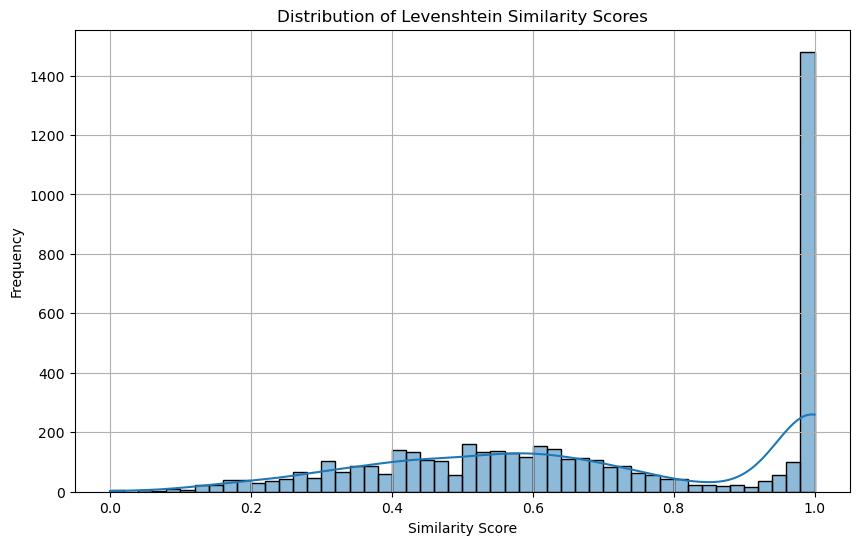

In [15]:
# Plotting the distribution using Seaborn
plt.figure(figsize=(10, 6))
sns.histplot(matching_df['levenshtein_similarity'], bins=50, kde=True)
plt.title('Distribution of Levenshtein Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [16]:
cut_offs = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9]

for cut_off in cut_offs:
    percentage_above = len(matching_df[matching_df["levenshtein_similarity"] > cut_off]) / len(matching_df)
    print(f"percentage of rows above {cut_off}: {percentage_above}")

percentage of rows above 0.5: 0.7019714765100671
percentage of rows above 0.55: 0.6453439597315436
percentage of rows above 0.6: 0.5721476510067114
percentage of rows above 0.65: 0.506501677852349
percentage of rows above 0.7: 0.44945469798657717
percentage of rows above 0.75: 0.40310402684563756
percentage of rows above 0.8: 0.37793624161073824
percentage of rows above 0.9: 0.35192953020134227


In [17]:
min_matching_df = matching_df[(matching_df["levenshtein_similarity"] > 0.6) & (matching_df["levenshtein_similarity"] < 0.65)]
min_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
22,Penfolds,Bin 95 Grange 2018,https://www.danmurphys.com.au/product/DM_23443...,Penfolds Grange 2018,https://www.vivino.com/AU/en/wines/169250169,True,0.611111,0.500000
29,Wolf Blass,House of the Dragon Cabernet Shiraz,https://www.danmurphys.com.au/product/DM_21723...,Wolf Blass House Of The Dragon Fire & Blood Ca...,https://www.vivino.com/AU/en/wines/172202337,True,0.603448,0.571429
30,Chapel Hill,The Vicar McLaren Vale Shiraz 2019,https://www.danmurphys.com.au/product/DM_21614...,Chapel Hill The Vicar Shiraz 2019,https://www.vivino.com/AU/en/wines/161795768,True,0.617647,0.600000
34,Sorby Adams,Jazz Eden Valley Rose 2021,https://www.danmurphys.com.au/product/DM_20924...,Sorby Adams Jazz Pinot Rosé 2021,https://www.vivino.com/AU/en/wines/169033756,True,0.615385,0.500000
36,Giodo,Toscana IGT,https://www.danmurphys.com.au/product/DM_20493...,Giodo Toscana Rosso,https://www.vivino.com/AU/en/wines/5008616,True,0.615385,0.333333
...,...,...,...,...,...,...,...,...
4724,Xanadu,Fusion Margaret River Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_89309...,Xanadu Fusion Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/160814724,True,0.625000,0.600000
4754,Tread Softly,Pinot Noir 375mL,https://www.danmurphys.com.au/product/DM_87407...,Tread Softly Pinot Noir,https://www.vivino.com/AU/en/wines/160740250,True,0.625000,0.666667
4759,Leconfield,Coonawarra Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_86912...,Leconfield Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/1951332,True,0.620690,0.666667
4762,Range Life,Pinot Nero 750mL,https://www.danmurphys.com.au/product/DM_86684...,Range Life Pinot Nero,https://www.vivino.com/AU/en/wines/159523857,True,0.625000,0.666667


In [18]:
#for i, row in min_matching_df.iterrows():
#    print(f"i={i} \"{row.dm_full_product_name}\"   ---   \"{row.vivino_product_name}   ---   {row.levenshtein_similarity}\"\n")

In [19]:
"""
i = 1110
print(min_matching_df.loc[i].dm_full_product_name)
print(min_matching_df.loc[i].dm_href)
print(min_matching_df.loc[i].vivino_product_name)
print(min_matching_df.loc[i].vivino_href)
print(min_matching_df.loc[i].levenshtein_similarity)
print(min_matching_df.loc[i].jaccard_similarity)
"""

'\ni = 1110\nprint(min_matching_df.loc[i].dm_full_product_name)\nprint(min_matching_df.loc[i].dm_href)\nprint(min_matching_df.loc[i].vivino_product_name)\nprint(min_matching_df.loc[i].vivino_href)\nprint(min_matching_df.loc[i].levenshtein_similarity)\nprint(min_matching_df.loc[i].jaccard_similarity)\n'

### Assess Jaccard similarity results

In [20]:
print(f"mean of similarity: {matching_df.jaccard_similarity.mean()}")
print(f"standard deviation of similarity: {matching_df.jaccard_similarity.std()}")

mean of similarity: 0.6963799777427084
standard deviation of similarity: 0.2717241643128746


/home/corey/anaconda3/envs/winevalet_env1/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


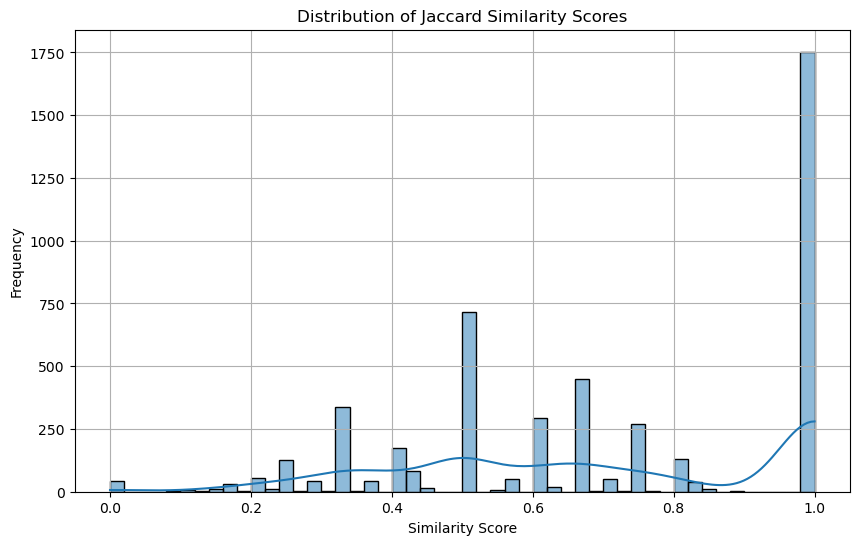

In [21]:
# Plotting the distribution using Seaborn
plt.figure(figsize=(10, 6))
sns.histplot(matching_df['jaccard_similarity'], bins=50, kde=True)
plt.title('Distribution of Jaccard Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [22]:
cut_offs = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9]

for cut_off in cut_offs:
    percentage_above = len(matching_df[matching_df["jaccard_similarity"] > cut_off]) / len(matching_df)
    print(f"percentage of rows above {cut_off}: {percentage_above}")

percentage of rows above 0.5: 0.6442953020134228
percentage of rows above 0.55: 0.6442953020134228
percentage of rows above 0.6: 0.5708892617449665
percentage of rows above 0.65: 0.5671140939597316
percentage of rows above 0.7: 0.47273489932885904
percentage of rows above 0.75: 0.40583053691275167
percentage of rows above 0.8: 0.37856543624161076
percentage of rows above 0.9: 0.36765939597315433


In [23]:
min_matching_df = matching_df[(matching_df["jaccard_similarity"] >= 0.4) & (matching_df["jaccard_similarity"] < 0.5)]
min_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
10,Wynns Coonawarra Estate,Davis Cabernet Sauvignon 2019,https://www.danmurphys.com.au/product/DM_23846...,Wynns Coonawarra Estate Barrel Series 13 Caber...,https://www.vivino.com/AU/en/wines/173320642,True,0.675000,0.428571
60,Chateau,Angelus 2018,https://www.danmurphys.com.au/product/DM_18339...,Château Angelus No. 3 D'Angélus Saint-Émilion ...,https://www.vivino.com/AU/en/wines/156851504,True,0.307692,0.400000
61,Tree of Life,Mix Berry Semi Sweet 2022,https://www.danmurphys.com.au/product/DM_ER_20...,Tree Of Life Mix Berry Red Semi-Sweet 2022,https://www.vivino.com/AU/en/wines/172412531,True,0.821429,0.428571
66,Wendouree,Clare Valley Shiraz 2017,https://www.danmurphys.com.au/product/DM_18008...,Wendouree Shiraz - Mataro 2017,https://www.vivino.com/AU/en/wines/155270129,True,0.333333,0.400000
68,Thistledown,Sands Of Time Grenache,https://www.danmurphys.com.au/product/DM_17928...,Thistledown Sands Of Time Old Vine Single Vine...,https://www.vivino.com/AU/en/wines/159585015,True,0.468085,0.428571
...,...,...,...,...,...,...,...,...
4589,Chris Ringland,Hoffman Shiraz 2006,https://www.danmurphys.com.au/product/DM_82358...,Chris Ringland HoffmanN Vineyard Shiraz 2006,https://www.vivino.com/AU/en/wines/2985198,True,0.655172,0.400000
4625,Château Faugères,Saint-Émilion 2010,https://www.danmurphys.com.au/product/DM_77394...,Château Faugères Saint-Émilion Grand Cru (Gran...,https://www.vivino.com/AU/en/wines/1889662,True,0.386364,0.400000
4656,Penfolds,Bin 407 Cab Sauv 2015,https://www.danmurphys.com.au/product/DM_68994...,Penfolds Bin 407 CabErnet SauvIgnon 2015,https://www.vivino.com/AU/en/wines/15690055,True,0.677419,0.428571
4670,Yalumba,Signature 2013,https://www.danmurphys.com.au/product/DM_66027...,Yalumba The Signature Cabernet Sauvignon - Shi...,https://www.vivino.com/AU/en/wines/2577674,True,0.311111,0.400000


In [24]:
for i, row in min_matching_df.iterrows():
    print(f"i={i} \"{row.dm_brand_name} {row.dm_product_name}\"   ---   \"{row.vivino_product_name}   ---   {row.jaccard_similarity}\"\n")   

i=10 "Wynns Coonawarra Estate Davis Cabernet Sauvignon 2019"   ---   "Wynns Coonawarra Estate Barrel Series 13 Cabernet Sauvignon 2019   ---   0.42857142857142855"

i=60 "Chateau Angelus 2018"   ---   "Château Angelus No. 3 D'Angélus Saint-Émilion 2018   ---   0.4"

i=61 "Tree of Life Mix Berry Semi Sweet 2022"   ---   "Tree Of Life Mix Berry Red Semi-Sweet 2022   ---   0.42857142857142855"

i=66 "Wendouree Clare Valley Shiraz 2017"   ---   "Wendouree Shiraz - Mataro 2017   ---   0.4"

i=68 "Thistledown Sands Of Time Grenache"   ---   "Thistledown Sands Of Time Old Vine Single Vineyard Grenache   ---   0.42857142857142855"

i=73 "Laurent Ponsot Griotte Chambertin Cuvée du Saule 2018"   ---   "Laurent Ponsot Cuvée Du Saule Griotte-Chambertin Grand Cru 2018   ---   0.4444444444444444"

i=81 "Parker Coonawarra Estate 95 Block Cabernet Sauvignon 2019"   ---   "Parker Coonawarra Estate Terra Rossa Cabernet Sauvignon 2019   ---   0.42857142857142855"

i=118 "Chateau Palmer 2015"   ---   "Cha

In [25]:
"""
i = 256
print(min_matching_df.loc[i].dm_full_product_name)
print(min_matching_df.loc[i].dm_href)
print(min_matching_df.loc[i].vivino_product_name)
print(min_matching_df.loc[i].vivino_href)
print(min_matching_df.loc[i].jaccard_similarity)
print(min_matching_df.loc[i].levenshtein_similarity)
"""

'\ni = 256\nprint(min_matching_df.loc[i].dm_full_product_name)\nprint(min_matching_df.loc[i].dm_href)\nprint(min_matching_df.loc[i].vivino_product_name)\nprint(min_matching_df.loc[i].vivino_href)\nprint(min_matching_df.loc[i].jaccard_similarity)\nprint(min_matching_df.loc[i].levenshtein_similarity)\n'

## Create and save final matching df

In [26]:
final_matching_df = matching_df[matching_df["jaccard_similarity"] >= 0.5].reset_index(drop=True)
final_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758,True,1.000000,1.000000
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True,0.466667,0.500000
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True,0.416667,0.500000
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True,0.400000,0.500000
4,Shingleback,D Block McLaren Vale Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91710...,Shingleback D Block Reserve Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/4731697,True,0.769231,0.500000
...,...,...,...,...,...,...,...,...
3783,Elephant In The Room,Tempranillo,https://www.danmurphys.com.au/product/DM_86526...,Elephant In The Room Titanic Tempranillo,https://www.vivino.com/AU/en/wines/165182546,True,0.578947,0.500000
3784,Brown Brothers,Winemakers Series Tempranillo Graciano,https://www.danmurphys.com.au/product/DM_86491...,Brown Brothers Winemaker’S Series Tempranillo ...,https://www.vivino.com/AU/en/wines/165373677,True,0.974359,1.000000
3785,Noble Fellows,Colonel Kiwi Marlborough Pinot Noir,https://www.danmurphys.com.au/product/DM_86484...,Noble Fellows Colonel Kiwi Pinot Noir,https://www.vivino.com/AU/en/wines/161072244,True,0.657143,0.800000
3786,Distant South,Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_86462...,Distant South Pinot Noir,https://www.vivino.com/AU/en/wines/160780353,True,0.526316,0.666667
